In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# Load dataset
df = pd.read_csv("products.csv")

# Remove exact duplicate rows
df = df.drop_duplicates()

# Convert pattern column into lists
df["detected_dark_patterns"] = (
    df["detected_dark_patterns"]
    .fillna("")
    .astype(str)
    .apply(lambda x: [p.strip() for p in x.split(";") if p.strip()])
)

# Count classified and unclassified products
df["pattern_count"] = df["detected_dark_patterns"].apply(len)

total = len(df)
classified = (df["pattern_count"] > 0).sum()
unclassified = total - classified

print("Total unique products:", total)
print("Classified products:", classified)
print("Unclassified products:", unclassified)


Total unique products: 159
Classified products: 141
Unclassified products: 18


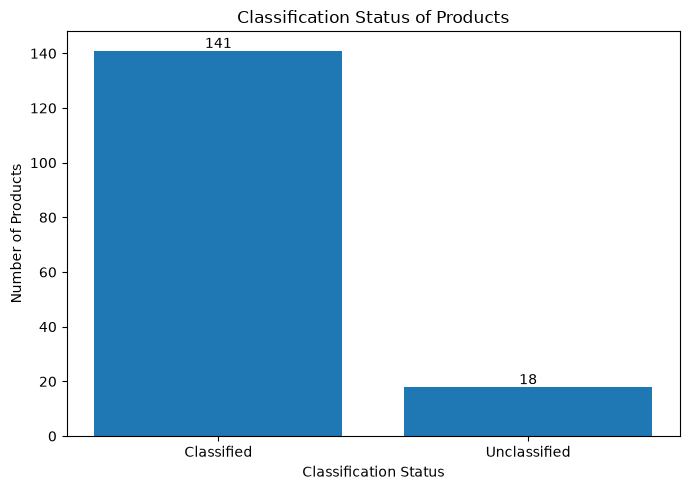

In [3]:
labels = ["Classified", "Unclassified"]
values = [classified, unclassified]

plt.figure(figsize=(7, 5))
plt.bar(labels, values)

plt.title("Classification Status of Products")
plt.xlabel("Classification Status")
plt.ylabel("Number of Products")

for i, value in enumerate(values):
    plt.text(i, value + 1, str(value), ha="center")

plt.tight_layout()
plt.show()


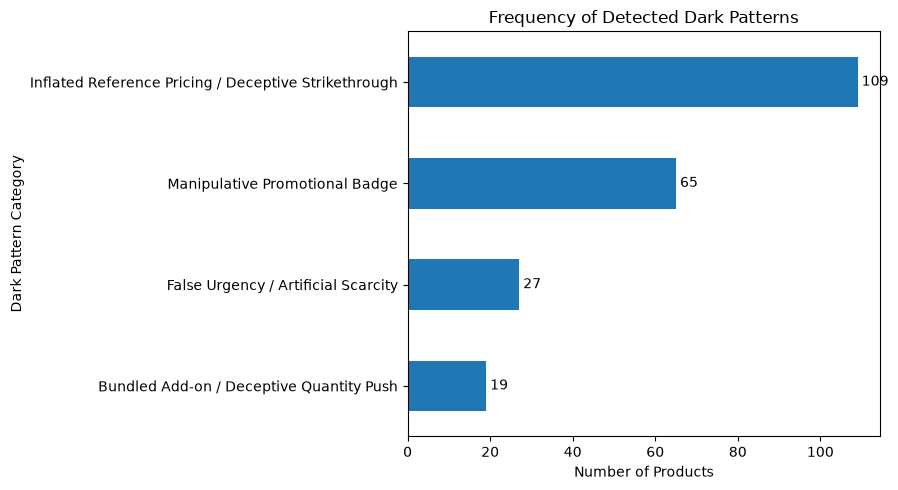

In [4]:
pattern_counts = df.explode("detected_dark_patterns")[
    "detected_dark_patterns"
].value_counts()

pattern_counts = pattern_counts[pattern_counts.index != ""]

plt.figure(figsize=(9, 5))
pattern_counts.sort_values().plot(kind="barh")

plt.title("Frequency of Detected Dark Patterns")
plt.xlabel("Number of Products")
plt.ylabel("Dark Pattern Category")

for i, value in enumerate(pattern_counts.sort_values()):
    plt.text(value + 1, i, str(value), va="center")

plt.tight_layout()
plt.show()


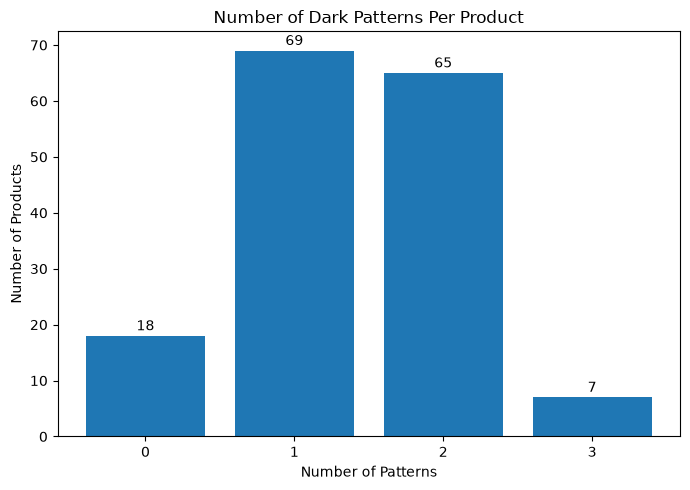

In [6]:

distribution = df["pattern_count"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(distribution.index.astype(str), distribution.values)

plt.title("Number of Dark Patterns Per Product")
plt.xlabel("Number of Patterns")
plt.ylabel("Number of Products")

for i, value in enumerate(distribution.values):
    plt.text(i, value + 1, str(value), ha="center")

plt.tight_layout()
plt.savefig("Num of dadrk patterns per product")
plt.show()


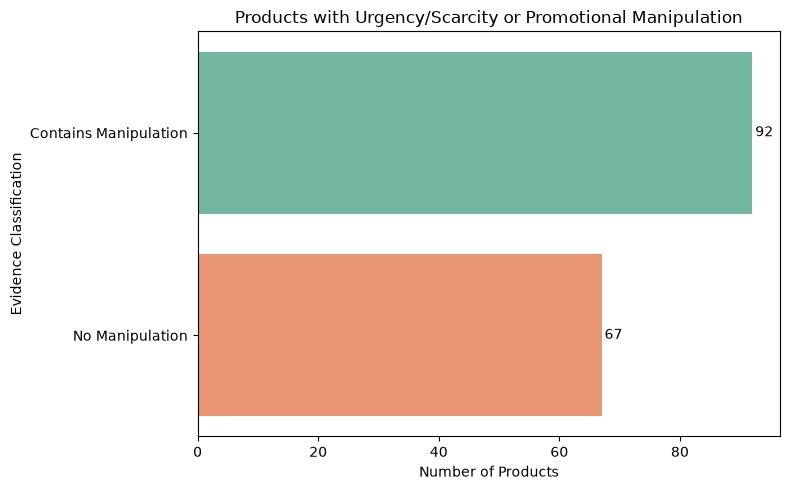

In [9]:
# Define keywords for urgency/scarcity and promotional manipulation
keywords = [
    'Only few left',
    'Hot Deal',
    'Big Billion Days Price',
    'Lowest price since launch',
    'Value 365'
]

# Create a new column flagging presence of manipulation
df['manipulation_flag'] = df['evidence_text'].apply(
    lambda x: any(keyword.lower() in str(x).lower() for keyword in keywords)
)

# Count products with vs. without manipulation
manip_counts = df['manipulation_flag'].value_counts()

# Horizontal bar chart
labels = manip_counts.index.map({
    True: 'Contains Manipulation',
    False: 'No Manipulation'
})

plt.figure(figsize=(8, 5))

sns.barplot(
    x=manip_counts.values,
    y=labels,
    palette="Set2"
)

plt.xlabel("Number of Products")
plt.ylabel("Evidence Classification")
plt.title("Products with Urgency/Scarcity or Promotional Manipulation")

# Display values
for i, value in enumerate(manip_counts.values):
    plt.text(value + 0.5, i, str(value), va='center')

plt.tight_layout()
plt.savefig("Manipulation & no manupulation")
plt.show()


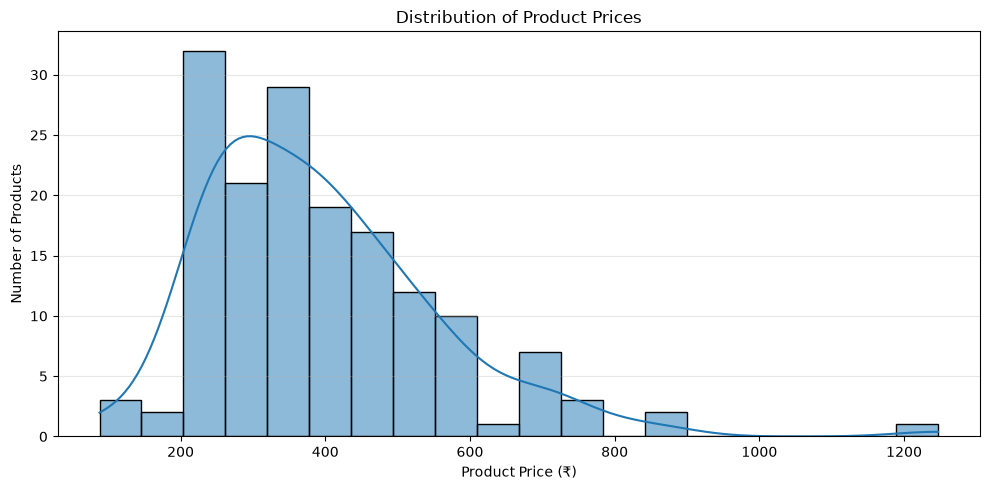

In [10]:
# Identify price column automatically
price_col = next(
    (col for col in df.columns if 'price' in col.lower().strip()),
    None
)

if price_col is None:
    print("Price column not found!")
    print("Available columns:", df.columns.tolist())

else:
    # Convert price values into numeric format
    df[price_col] = pd.to_numeric(
        df[price_col].astype(str).str.replace(r'[^\d.]', '', regex=True),
        errors='coerce'
    )

    # Plot price distribution
    plt.figure(figsize=(10, 5))

    sns.histplot(data=df, x=price_col, bins=20, kde=True)

    plt.title('Distribution of Product Prices')
    plt.xlabel('Product Price (₹)')
    plt.ylabel('Number of Products')
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

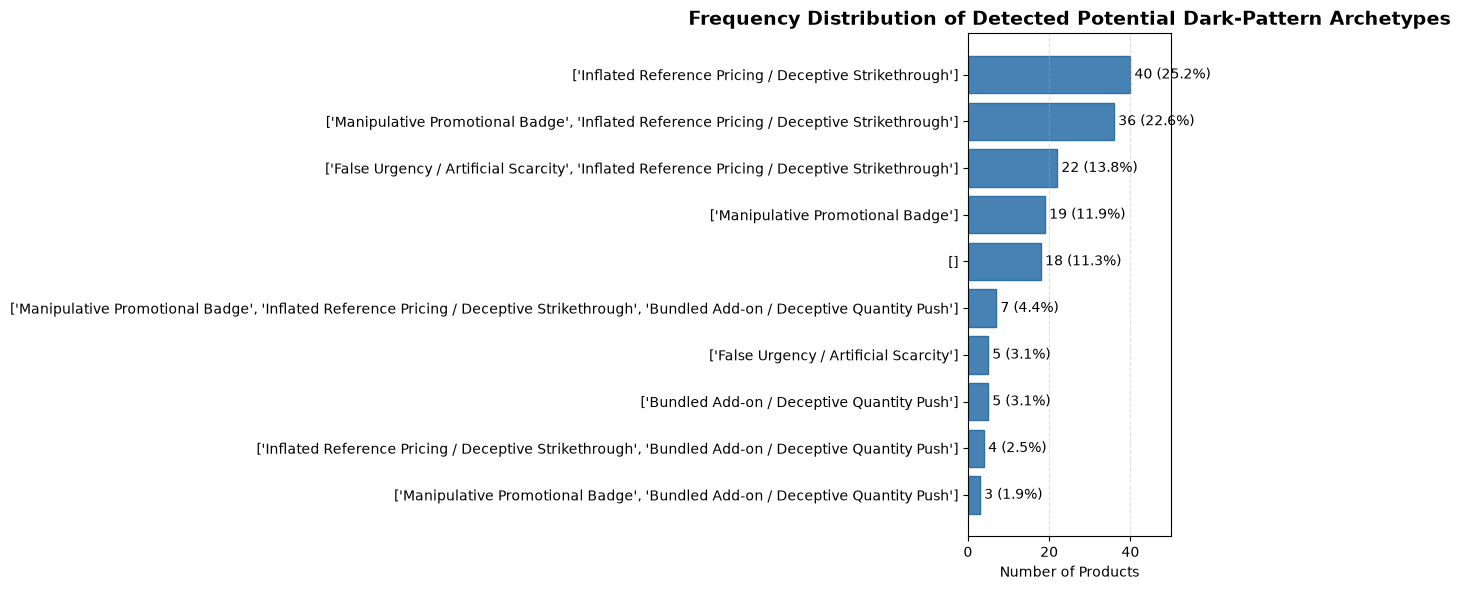

In [11]:
from collections import Counter

pattern_counts = Counter()

for patterns in df['detected_dark_patterns'].dropna():
    unique_patterns = set(
        p.strip() for p in str(patterns).split(';') if p.strip()
    )
    for pattern in unique_patterns:
        pattern_counts[pattern] += 1

patterns = sorted(
    pattern_counts.items(),
    key=lambda x: x[1]
)

labels = [x[0] for x in patterns]
counts = [x[1] for x in patterns]
percentages = [x / len(df) * 100 for x in counts]

plt.figure(figsize=(12, 6))

bars = plt.barh(
    labels,
    counts,
    color='steelblue',
    edgecolor='#2F6FA5'
)

plt.title(
    'Frequency Distribution of Detected Potential Dark-Pattern Archetypes',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Number of Products')
plt.grid(axis='x', linestyle='--', alpha=0.4)

for bar, count, percentage in zip(bars, counts, percentages):
    plt.text(
        count + 1,
        bar.get_y() + bar.get_height()/2,
        f'{count} ({percentage:.1f}%)',
        va='center'
    )

plt.xlim(0, max(counts) * 1.25)
plt.tight_layout()
plt.show()
